# Handoff 상태 전환

**이 노트북에서 할 일**

1. 모델 없이, 노드가 담당을 넘기고 체크포인터가 다음 차례의 담당을 이어 주는 그래프를 만듭니다.
2. 도구가 담당을 넘길 때 도구 메시지가 빠지면 생기는 일을, 손으로 만든 응답으로 봅니다.
3. 실제 모델이 넘기기 도구로 담당을 넘기는 두 차례 대화에서, 응답을 쓴 담당과 요청 수를 셉니다.

**준비물** — 2~5절은 모델을 부르지 않아 API 키 없이 실행됩니다.
6~7절은 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 7절에서 같은 스레드로 두 차례 실행합니다.
첫 차례에 담당을 넘기면 요청이 2번, 둘째 차례가 1번이라 모두 3번입니다.
요금표로 어림한 예상 비용은 0.002달러 아래이고, 청구 금액이 아닙니다.

2~5절에서 모델을 뺀 것은 넘기는 구조와 체크포인터의 동작을 실행마다 같은 값으로 먼저 보려는 것입니다.
모델의 답 글과 넘기는지는 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없고, 체크포인트는 프로그램 메모리에만 둡니다.
앞 챕터에서 배운 함수 둘은 도구 파일 `delegation_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절과 6절을 읽습니다.
노드와 도구가 담당을 넘기는 모양과, 다음 차례가 받은 담당에서 시작하는 자리입니다.
4~5절은 넘길 이름과 도구 메시지를 바꿔 보는 자리이고, 7절은 모델을 부르는 실행입니다.
이 두 자리는 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch26-delegation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 회색 원통 InMemorySaver 스레드마다 담당 칸 저장이 다음 차례에 읽음이라는 선으로 그 아래 회색 둥근 상자 START 시작점 조건 함수 pick_desk가 담당 칸을 읽고 고름과 이어집니다. 시작점에서 점선 둘이 나가, 담당 칸이 빈 글이면 파란 상자 loan_desk 대출 규정 담당 Command로 넘기거나 답함으로, 담당 칸이 interlibrary_desk면 파란 상자 interlibrary_desk 상호대차 담당으로 갑니다. loan_desk에서 goto interlibrary_desk 점선이 상호대차 담당으로, goto END 점선이 회색 둥근 상자 END 끝점으로 갑니다. 상호대차 담당에서는 실선이 끝점으로 가는 그림](attachment:02-1-코드가-넘기는-두-담당.png)

위에서 아래로 읽습니다.
시작점 아래 점선과 실선의 자리는 노트북 2절에서 출력한 구조 문자열의 화살표 다섯 줄과 같습니다.
파란 상자는 우리가 적은 노드이고, 회색 둥근 상자는 시작점과 끝점입니다.
조건 함수 pick_desk는 노드가 아니어서 따로 상자를 두지 않고 시작점 상자 안에 적었습니다.
맨 위 회색 원통은 체크포인터이고, 선은 다음 차례에 조건 함수가 저장된 담당 칸을 읽는다는 뜻입니다.
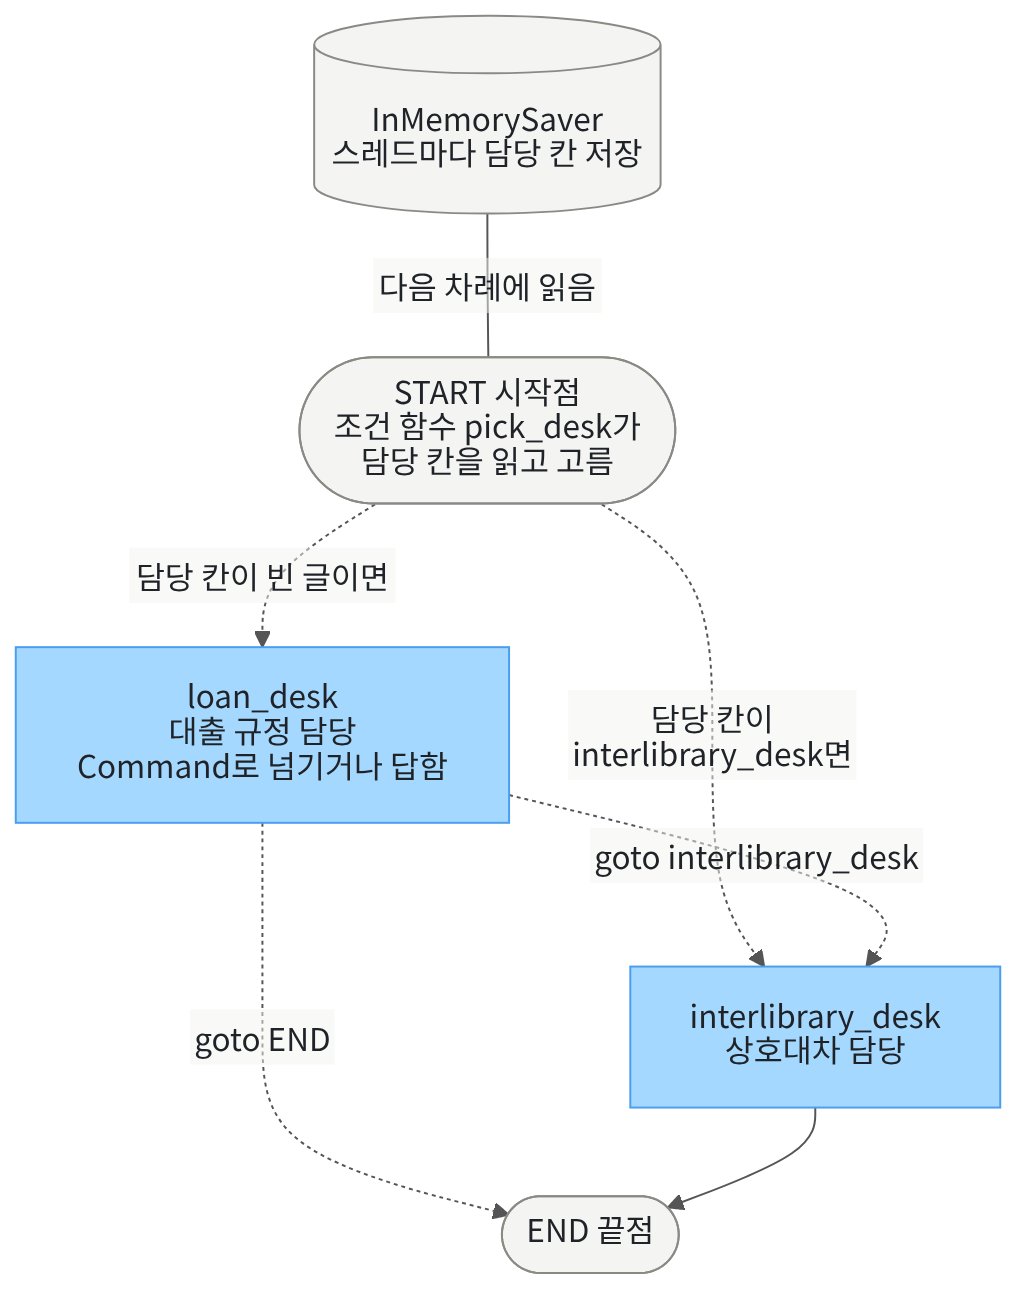

## 1. 준비

이 절에서는 담당끼리 문의를 넘기는 모양을 봅니다.
절 제목의 Handoff는 핸드오프를 가리키고, 뜻은 2절에서 풉니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.
체크포인터 `InMemorySaver`가 든 패키지는 langgraph를 설치하면 함께 설치됩니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프를 만드는 이름은 Ch 13에서 썼습니다.
체크포인터 `InMemorySaver`는 Ch 23 01절, 도구 실행 노드 `ToolNode`는 Ch 20 01절에서 썼습니다.
실행 객체 표시 `ToolRuntime`은 Ch 21 03절, 메시지 클래스 `ToolMessage`는 Ch 19 05절에서 보았습니다.

In [2]:
# 상태 형식(Ch 13 01·02절)·그래프와 Command(Ch 13 06절)·체크포인터(Ch 23 01절) 이름을 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.types import Command
# 에이전트(Ch 21 01절)·모델(Ch 6 01절)·메시지(Ch 13 04절·Ch 19 05절)·도구(Ch 19 01절·Ch 21 03절) 이름을 가져옵니다
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, AnyMessage, HumanMessage, ToolMessage
from langchain.tools import ToolRuntime, tool
# 앞 챕터에서 배운 함수 둘은 도구 파일에서 가져옵니다
from delegation_tools import show_messages, sum_usage

print("도구 파일에서 가져온 함수:", "show_messages, sum_usage")

도구 파일에서 가져온 함수: show_messages, sum_usage


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: show_messages, sum_usage`가 보입니다.
Ch 19 06절 함수 `show_messages`는 메시지 목록을 한 줄씩 출력합니다.
Ch 19 05절 함수 `sum_usage`는 목록 안 응답마다 요청 하나로 세고 토큰을 더합니다.

앞에서 배운 함수는 `delegation_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

## 2. 코드가 담당을 넘기는 그래프

01절에서는 중앙 에이전트가 대출 규정 담당에게 일을 맡기고 답을 받아 왔습니다.
이 절에서는 문의한 사람이 담당과 바로 이야기하고, 담당이 다음 담당에게 문의를 넘깁니다.
이렇게 다음 차례에 대화할 담당 자체를 바꾸는 일을 핸드오프(handoff)라고 부릅니다.
전화 상담원이 담당 부서로 전화를 연결해 주면, 그다음 말은 그 부서 직원과 나누는 것과 같습니다.
이 절 코드에서는 노드가 `Command`로 다음 노드를 고르고, 칸 `active_agent`에 새 담당 이름을 남깁니다.

담당은 01절의 대출 규정 담당 `loan_desk`와, 새로 둔 상호대차 담당 `interlibrary_desk` 둘입니다.
상호대차는 다른 도서관의 책을 빌려 오는 일입니다.
2~5절은 모델을 부르지 않고, 담당 노드가 코드로 정한 규칙대로 넘깁니다.

먼저 상태 형식을 만듭니다.
칸 `active_agent`에는 다음 차례에 대화할 담당 이름을 적고, 이 절에서는 담당 칸이라고 부릅니다.
칸 `trace`에는 Ch 13 02절처럼 이어 붙이기 규칙을 적어, 지난 노드 이름이 쌓이게 합니다.

In [3]:
# 문의 글·담당 칸·답 칸·실행 흔적 칸을 둔 상태 형식을 만듭니다(실행 흔적 칸에만 Ch 13 02절 이어 붙이기 규칙)
class DeskState(TypedDict):
    message: str
    active_agent: str
    reply: str
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 넷 가운데 규칙을 적은 칸은 실행 흔적 칸 하나이고, 나머지 셋은 새 값이 오면 덮어씁니다.
체크포인터를 붙이면 실행 흔적 칸은 같은 스레드에서 차례를 넘어 계속 쌓입니다.

다음 셀은 첫 담당인 대출 규정 담당 노드입니다.
문의 글에 「다른 도서관」이 있으면 상호대차 담당에게 넘기고, 없으면 직접 답합니다.
넘길 때는 Ch 13 06절처럼 `Command` 하나에 담당 칸 갱신과 다음 노드 이름을 함께 담습니다.

In [4]:
# 첫 담당(대출 규정 담당) 노드입니다. 글에 「다른 도서관」이 있으면 상호대차 담당에게 넘기고, 없으면 직접 답합니다
def loan_desk(state):
    if "다른 도서관" in state["message"]:
        # 담당 칸 갱신과 다음 노드 이름을 Command 하나에 함께 담습니다(Ch 13 06절)
        update = {"active_agent": "interlibrary_desk", "trace": ["loan_desk"]}
        return Command(goto="interlibrary_desk", update=update)
    # 직접 답할 때는 다음 노드 이름으로 끝점 END를 적습니다
    update = {"active_agent": "loan_desk", "reply": "대출 규정 담당이 답합니다", "trace": ["loan_desk"]}
    return Command(goto=END, update=update)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
넘기는 쪽 갱신에는 답 칸이 없어, 답은 받은 담당이 씁니다.
두 쪽 모두 담당 칸에는 다음 차례에 대화할 담당 이름을 적습니다.
넘길지는 이 셀의 글자 규칙이 정하고, 6절에서는 모델이 정합니다.

다음 셀은 상호대차 담당 노드입니다.

In [5]:
# 상호대차 담당 노드입니다. 답 칸과 실행 흔적 칸에 자기 몫만 냅니다
def interlibrary_desk(state):
    return {"reply": "상호대차 담당이 답합니다", "trace": ["interlibrary_desk"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
상호대차 담당은 담당 칸을 건드리지 않고, 답 칸과 실행 흔적 칸에 자기 몫만 냅니다.
답 글은 교재용으로 정한 한 줄이고, 누가 답했는지만 보여 줍니다.

다음 셀은 시작점 `START` 뒤에 둘 조건 함수입니다.
Ch 20 04절처럼 시작점 뒤에 조건부 엣지를 두면, 상태를 보고 첫 노드를 고를 수 있습니다.
이 함수는 저장된 담당 칸을 읽어, 상호대차 담당이면 그 노드에서 시작하게 합니다.

In [6]:
# 시작점 뒤에 둘 조건 함수입니다. 저장된 담당 칸을 읽어, 이번 차례를 시작할 노드 이름을 내놓습니다
def pick_desk(state):
    if state["active_agent"] == "interlibrary_desk":
        return "interlibrary_desk"
    return "loan_desk"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담당 칸이 빈 글이거나 `loan_desk`이면 첫 담당에서 시작합니다.
조건 함수는 노드가 아니라, 조건부 엣지가 부르는 함수입니다.

다음 셀은 두 노드와 조건 함수로 그래프를 만들고 체크포인터를 붙입니다.
노드 `loan_desk`를 등록할 때는 인자 `destinations`에 갈 수 있는 곳을 적습니다.
Ch 13 06절처럼 이 인자는 실행이 아니라 구조 문자열에만 쓰입니다.

In [7]:
# 두 담당 노드와 조건 함수로 그래프를 만들고, 체크포인터를 붙여 컴파일합니다
desk_builder = StateGraph(DeskState)
# 인자 destinations는 이 노드의 Command가 갈 수 있는 곳이고, 구조 문자열에만 쓰입니다(Ch 13 06절)
desk_builder.add_node("loan_desk", loan_desk, destinations=("interlibrary_desk", END))
desk_builder.add_node("interlibrary_desk", interlibrary_desk)
desk_builder.add_conditional_edges(START, pick_desk, ["loan_desk", "interlibrary_desk"])
desk_builder.add_edge("interlibrary_desk", END)
desk_graph = desk_builder.compile(checkpointer=InMemorySaver())
print("등록한 노드:", list(desk_builder.nodes))

등록한 노드: ['loan_desk', 'interlibrary_desk']


**결과 읽기** — 출력 줄 `등록한 노드: ['loan_desk', 'interlibrary_desk']`가 보입니다.
조건 함수 `pick_desk`는 노드로 등록하지 않아 이 목록에 없습니다.

다음 셀은 그래프가 그린 구조 문자열에서 화살표가 있는 줄만 출력합니다.

In [8]:
# 그래프가 스스로 그린 구조 문자열에서 화살표가 있는 줄만 골라 출력합니다(Ch 13 06절과 같은 모양)
structure_text = desk_graph.get_graph().draw_mermaid()
print("구조 문자열에서 화살표가 있는 줄:")
for line in structure_text.split("\n"):
    if "->" in line:
        print(line.strip())

구조 문자열에서 화살표가 있는 줄:
__start__ -.-> interlibrary_desk;
__start__ -.-> loan_desk;
loan_desk -.-> __end__;
loan_desk -.-> interlibrary_desk;
interlibrary_desk --> __end__;


**결과 읽기** — 라벨 줄 아래에 화살표 줄 다섯이 보입니다.
줄 `__start__ -.-> loan_desk;`와 `__start__ -.-> interlibrary_desk;`는 조건 함수가 고를 두 시작 노드입니다.
줄 `loan_desk -.-> interlibrary_desk;`와 `loan_desk -.-> __end__;`는 적어 둔 목적지라 점선입니다.
줄 `interlibrary_desk --> __end__;`만 실선인 고정 엣지입니다.

## 3. 같은 스레드에서 두 차례 묻기

첫 차례에는 다른 도서관의 책을 묻고, 둘째 차례에는 신청하면 며칠 뒤에 받는지 묻습니다.
둘째 글에는 「다른 도서관」이 없어, 첫 담당이 받으면 직접 답합니다.
실행 전에 예상해 봅니다.
같은 스레드라면 둘째 차례는 저장된 담당 칸을 읽고 상호대차 담당에서 바로 시작할 것입니다.

다음 셀은 스레드 `desk-1`에 첫 글을 넣어 실행합니다.
실행 뒤 Ch 23 01절 메서드 `get_state`로 저장된 마지막 체크포인트를 읽습니다.

In [9]:
# 스레드 desk-1에 첫 글을 넣어 실행하고, 저장된 마지막 체크포인트를 읽습니다(Ch 23 01절)
first_question = "다른 도서관에 있는 책도 빌려 볼 수 있나요?"
desk_config = {"configurable": {"thread_id": "desk-1"}}
first_input = {"message": first_question, "active_agent": "", "reply": "", "trace": []}
first_result = desk_graph.invoke(first_input, desk_config)
print("담당 칸:", first_result["active_agent"], "| 답 칸:", first_result["reply"])
print("실행 흔적 칸:", first_result["trace"])
saved = desk_graph.get_state(desk_config)
print("저장된 담당 칸:", saved.values["active_agent"])
print("다음에 실행할 노드:", saved.next)

담당 칸: interlibrary_desk | 답 칸: 상호대차 담당이 답합니다
실행 흔적 칸: ['loan_desk', 'interlibrary_desk']
저장된 담당 칸: interlibrary_desk
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `담당 칸: interlibrary_desk | 답 칸: 상호대차 담당이 답합니다`가 보입니다.
출력 줄 `실행 흔적 칸: ['loan_desk', 'interlibrary_desk']`로, 첫 담당이 넘기고 받은 담당이 답했습니다.
출력 줄 `저장된 담당 칸: interlibrary_desk`는 체크포인트에 남은 값입니다.
출력 줄 `다음에 실행할 노드: ()`는 그래프가 끝까지 실행되어 남은 노드가 없다는 뜻입니다.

다음 셀은 같은 스레드에 둘째 글만 넣어 실행합니다.
담당 칸·답 칸·실행 흔적 칸은 넣지 않고, 체크포인트에 저장된 값을 씁니다.

In [10]:
# 같은 스레드에 둘째 글만 넣어 실행하고, 이번 차례에 더해진 실행 흔적만 잘라 봅니다
second_question = "신청하면 며칠 뒤에 받을 수 있나요?"
second_result = desk_graph.invoke({"message": second_question}, desk_config)
first_count = len(first_result["trace"])
second_trace = second_result["trace"][first_count:]
print("담당 칸:", second_result["active_agent"], "| 답 칸:", second_result["reply"])
print("실행 흔적 칸:", second_result["trace"])
print("이번 차례에 지난 노드:", second_trace)

담당 칸: interlibrary_desk | 답 칸: 상호대차 담당이 답합니다
실행 흔적 칸: ['loan_desk', 'interlibrary_desk', 'interlibrary_desk']
이번 차례에 지난 노드: ['interlibrary_desk']


**결과 읽기** — 출력 줄 `이번 차례에 지난 노드: ['interlibrary_desk']`가 보입니다.
둘째 차례는 첫 담당을 건너뛰고 상호대차 담당에서 바로 시작했습니다.
조건 함수가 체크포인트에 저장된 담당 칸 `interlibrary_desk`를 읽었기 때문입니다.
출력 줄 `실행 흔적 칸: ['loan_desk', 'interlibrary_desk', 'interlibrary_desk']`에는 앞 차례 흔적 뒤에 이름 하나가 더해졌습니다.

같은 스레드에서는 저장된 칸 값에서 시작하고, 새 입력에 넣은 칸만 바뀝니다.
그래서 담당 칸은 첫 차례에 넘겨받은 값 그대로였습니다.

다음 셀은 값 하나만 바꿔 봅니다.
바꿀 값은 스레드 이름이고, 같은 둘째 글을 새 스레드 `desk-2`에 넣습니다.
새 스레드에는 저장된 칸이 없어, Ch 23 01절처럼 칸을 모두 채운 입력을 넣습니다.
실행 전에 예상해 봅니다.
저장된 담당이 없으니 첫 담당에서 시작하고, 첫 담당이 직접 답할 것입니다.

In [11]:
# 값 바꿔 보기: 스레드 이름만 desk-2로 바꾸고, 새 스레드라 칸을 모두 채운 입력으로 둘째 글을 넣습니다
other_config = {"configurable": {"thread_id": "desk-2"}}
other_input = {"message": second_question, "active_agent": "", "reply": "", "trace": []}
other_result = desk_graph.invoke(other_input, other_config)
print("담당 칸:", other_result["active_agent"], "| 답 칸:", other_result["reply"])
print("실행 흔적 칸:", other_result["trace"])

담당 칸: loan_desk | 답 칸: 대출 규정 담당이 답합니다
실행 흔적 칸: ['loan_desk']


**결과 읽기** — 출력 줄 `담당 칸: loan_desk | 답 칸: 대출 규정 담당이 답합니다`가 보입니다.
출력 줄 `실행 흔적 칸: ['loan_desk']`로, 새 스레드는 첫 담당에서 시작했습니다.
같은 둘째 글이라도 어느 스레드로 보내느냐에 따라 받는 담당이 달랐습니다.
다음 차례의 담당은 글이 아니라, 스레드에 저장된 담당 칸이 정합니다.

## 4. 넘길 노드 이름을 잘못 적으면

넘길 노드 이름은 `goto`에 글로 적습니다.
이 글에 오타가 있으면 어떻게 되는지 봅니다.
바꿀 값은 첫 담당 노드가 적는 다음 노드 이름입니다.

In [12]:
# 넘길 노드 이름에서 글자 하나(e)를 빠뜨린 첫 담당 노드입니다(interlibrary_desk가 아니라 interlibrary_dsk)
def loan_desk_typo(state):
    update = {"active_agent": "interlibrary_desk", "trace": ["loan_desk"]}
    return Command(goto="interlibrary_dsk", update=update)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담당 칸에는 `interlibrary_desk`를 바르게 적고, 다음 노드 이름만 글자 하나를 빠뜨렸습니다.
이 그래프에는 이름이 `interlibrary_dsk`인 노드가 없습니다.

다음 셀은 이 노드를 첫 담당 자리에 둔 작은 그래프를 새로 만들어, 3절의 첫 글로 실행합니다.
2절 그래프와 달리 시작 엣지는 고정이고, 체크포인터와 `destinations`는 두지 않았습니다.
실행 전에 예상해 봅니다.
없는 노드로 가라고 했으니 오류가 날 것 같습니다.

In [13]:
# 오타 난 노드를 첫 담당 자리에 둔 그래프를 만들어, 3절의 첫 글로 실행합니다(체크포인터 없음)
typo_builder = StateGraph(DeskState)
typo_builder.add_node("loan_desk", loan_desk_typo)
typo_builder.add_node("interlibrary_desk", interlibrary_desk)
typo_builder.add_edge(START, "loan_desk")
typo_builder.add_edge("interlibrary_desk", END)
typo_result = typo_builder.compile().invoke(first_input)
print("담당 칸:", typo_result["active_agent"])
print("실행 흔적 칸:", typo_result["trace"])
print("답 칸이 빈 글인가:", typo_result["reply"] == "")

Task loan_desk with path ('__pregel_pull', 'loan_desk') wrote to unknown channel branch:to:interlibrary_dsk, ignoring it.


담당 칸: interlibrary_desk
실행 흔적 칸: ['loan_desk']
답 칸이 빈 글인가: True


**결과 읽기** — 오류 없이 셀이 끝났고, 출력 줄 `실행 흔적 칸: ['loan_desk']`가 보입니다.
상호대차 담당은 실행되지 않았고, 출력 줄 `답 칸이 빈 글인가: True`처럼 아무도 답하지 않았습니다.
그런데 출력 줄 `담당 칸: interlibrary_desk`는 넘긴 것처럼 바뀌었습니다.
출력에는 경고 글 한 줄이 함께 보이고, 이 글만 이름이 틀렸다는 것을 알려 줍니다.

경고 글 끝의 `wrote to unknown channel branch:to:interlibrary_dsk, ignoring it.`은 없는 이름으로 가려던 값을 버렸다는 뜻입니다.
설치판 langgraph 1.2.11 `pregel/_algo.py` 311~313행이 이 경고만 남기고 넘어가는 자리입니다.
이 글은 파이썬 표준 모듈 `logging`으로 남긴 경고라, 기록 설정에 따라 보이지 않을 수도 있습니다.
이름 오타는 실행을 멈추지 않으므로, 넘긴 뒤에는 실행 흔적 칸처럼 지나간 노드를 출력해 보는 편이 안전합니다.

## 5. 도구가 넘길 때는 도구 메시지를 함께

6절에서는 모델이 도구를 불러 담당을 넘깁니다.
도구가 내놓는 `Command`에는 지켜야 할 약속이 하나 있습니다.
Ch 19 05절에서 본 것처럼, 도구 요청 하나에는 같은 호출 ID의 도구 메시지가 짝지어 있어야 합니다.
이 절에서는 모델 없이, Ch 20 01절처럼 손으로 만든 응답으로 이 약속을 봅니다.

다음 셀은 메시지 칸과 담당 칸을 둔 상태 형식입니다.
칸 구성이 2절과 달라 이름을 새로 붙이고, 6~7절의 바깥 그래프도 이 형식을 씁니다.

In [14]:
# 메시지 칸(Ch 13 04절 메시지 규칙)과 담당 칸을 둔 상태 형식을 만듭니다(5~7절에서 씀)
class TeamState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    active_agent: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸에는 Ch 13 04절 메시지 규칙 `add_messages`를 적었습니다.
담당 칸에는 규칙을 적지 않아 새 값이 오면 덮어씁니다.

다음 두 셀은 도구 메시지 없이 담당을 넘기는 도구 둘입니다.
첫 도구는 지금 그래프의 담당 칸만 바꾸는 `Command`를 내놓습니다.

함수 위의 `@tool` 줄은 데코레이터 줄입니다.
데코레이터 줄은 함수 위에 붙여 그 함수를 다른 것으로 감싸는 표시이고, 뜻은 Ch 2 09절에 있습니다.
이 셀에서는 이 줄이 아래 함수를 도구로 등록하고, Ch 19 01절처럼 독스트링이 도구 설명이 됩니다.

In [15]:
# 도구 메시지 없이, 지금 그래프의 담당 칸만 바꾸는 Command를 내놓는 도구입니다
@tool
def hand_off_plain():
    """상호대차 담당에게 넘깁니다(도구 메시지를 넣지 않고, 지금 그래프로)."""
    return Command(update={"active_agent": "interlibrary_desk"})

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 도구에는 모델이 넘길 인자가 없고, 담당 칸 갱신 하나만 담은 `Command`를 내놓습니다.
갱신에 메시지 칸이 없으니, 도구 요청에 답하는 도구 메시지도 없습니다.

다음 셀의 둘째 도구는 인자 `graph=Command.PARENT`를 더합니다.
도구를 부른 그래프가 다른 그래프의 노드로 들어 있을 때, 그 바깥 그래프에서 `goto` 노드를 찾으라는 표시입니다.
설치판 langgraph 1.2.11 `types.py` 806행은 이 값을 가장 가까운 바깥 그래프라고 적습니다.

In [16]:
# 도구 메시지 없이, 바깥 그래프의 상호대차 담당 노드로 가는 Command를 내놓는 도구입니다
@tool
def hand_off_parent():
    """상호대차 담당에게 넘깁니다(도구 메시지를 넣지 않고, 바깥 그래프로)."""
    update = {"active_agent": "interlibrary_desk"}
    # graph=Command.PARENT는 이 그래프를 노드로 둔 바깥 그래프에서 goto 노드를 찾으라는 표시입니다
    return Command(goto="interlibrary_desk", update=update, graph=Command.PARENT)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
갱신과 다음 노드 이름은 2절 첫 담당 노드와 같은 모양이고, 가는 그래프만 다릅니다.
이 도구도 도구 메시지를 넣지 않았습니다.

다음 셀은 두 도구를 가진 도구 실행 노드 하나로 작은 그래프를 만듭니다.

In [17]:
# 두 도구를 가진 도구 실행 노드(Ch 20 01절) 하나로 작은 그래프를 만듭니다
tools_builder = StateGraph(TeamState)
tools_builder.add_node("tools", ToolNode([hand_off_plain, hand_off_parent]))
tools_builder.add_edge(START, "tools")
tools_builder.add_edge("tools", END)
tools_graph = tools_builder.compile()
print("등록한 노드:", list(tools_builder.nodes))

등록한 노드: ['tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['tools']`가 보입니다.
시작점에서 도구 실행 노드로 가고, 도구 실행 노드에서 끝나는 그래프입니다.

다음 셀은 모델을 부르지 않고, 첫 도구를 요청하는 응답을 손으로 만들어 넣습니다.
응답에 담는 도구 요청은 Ch 19 04절의 칸 넷(`name`·`args`·`id`·`type`)입니다.
올라오는 오류는 Ch 23 01절처럼 이 셀에서만 이름을 적어 받고 출력합니다.

In [18]:
# 모델 없이, hand_off_plain 요청을 담은 응답을 손으로 만들어 넣고 올라온 오류를 받아 출력합니다
plain_call = {"name": "hand_off_plain", "args": {}, "id": "hand_call_1", "type": "tool_call"}
plain_request = AIMessage(content="", tool_calls=[plain_call])
try:
    tools_graph.invoke({"messages": [plain_request], "active_agent": ""})
except ValueError as error:
    error_text = str(error)
    print("받은 오류:", type(error).__name__)
    print("오류 글 앞부분:", error_text[:66])

받은 오류: ValueError
오류 글 앞부분: Expected to have a matching ToolMessage in Command.update for tool


**결과 읽기** — 출력 줄 `받은 오류: ValueError`가 보입니다.
오류 글은 `Expected to have a matching ToolMessage in Command.update for tool`로 시작합니다.
도구 요청에 짝이 되는 도구 메시지가 `Command`의 갱신에 없다는 뜻입니다.
지금 그래프로 가는 `Command`는 도구 실행 노드가 이 짝을 검사합니다.

다음 셀은 둘째 도구가 갈 바깥 그래프의 받는 쪽 노드입니다.
상호대차 담당이 답한 것처럼, 응답 한 줄을 손으로 적어 냅니다.

In [19]:
# 바깥 그래프의 받는 쪽 노드입니다. 상호대차 담당의 답 한 줄을 손으로 적어 냅니다(모델 없음)
def interlibrary_note(state):
    note = AIMessage(content="상호대차 담당이 답합니다.")
    return {"messages": [note]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델을 부르지 않고, 정해 둔 글을 응답으로 내놓는 보통 함수입니다.

다음 셀은 앞에서 만든 작은 그래프를 첫 담당 노드로 등록한 바깥 그래프를 만듭니다.
메서드 `add_node`에 함수 대신 컴파일한 그래프를 넘기면, 그 그래프가 노드 하나로 실행됩니다.
이렇게 다른 그래프의 노드로 들어간 그래프를 하위 그래프라고 부릅니다.
한 부서가 안에서 일을 나눠 해도, 회사 조직도에서는 칸 하나로 보이는 것과 같습니다.

In [20]:
# 앞에서 만든 작은 그래프를 첫 담당 노드로 등록한 바깥 그래프를 만듭니다(작은 그래프는 하위 그래프가 됨)
outer_builder = StateGraph(TeamState)
outer_builder.add_node("loan_desk", tools_graph)
outer_builder.add_node("interlibrary_desk", interlibrary_note)
outer_builder.add_edge(START, "loan_desk")
outer_builder.add_edge("interlibrary_desk", END)
outer_graph = outer_builder.compile()
print("바깥 그래프의 노드:", list(outer_builder.nodes))

바깥 그래프의 노드: ['loan_desk', 'interlibrary_desk']


**결과 읽기** — 출력 줄 `바깥 그래프의 노드: ['loan_desk', 'interlibrary_desk']`가 보입니다.
노드 `loan_desk`의 속은 도구 실행 노드 하나를 가진 작은 그래프이고, 이 그래프가 하위 그래프입니다.

다음 셀은 둘째 도구를 요청하는 응답을 손으로 만들어, 사람 글 뒤에 붙여 넣습니다.
실행 전에 예상해 봅니다.
도구 메시지가 없으니 이번에도 오류가 날 것 같습니다.

In [21]:
# 사람 글 뒤에 hand_off_parent 요청을 담은 응답을 손으로 붙여 바깥 그래프를 실행하고, 메시지 목록을 봅니다
parent_call = {"name": "hand_off_parent", "args": {}, "id": "hand_call_2", "type": "tool_call"}
parent_request = AIMessage(content="", tool_calls=[parent_call])
outer_input = {"messages": [HumanMessage(content=first_question), parent_request], "active_agent": ""}
outer_result = outer_graph.invoke(outer_input)
print("담당 칸:", outer_result["active_agent"])
print("메시지 목록:")
show_messages(outer_result["messages"])

담당 칸: interlibrary_desk
메시지 목록:
HumanMessage
AIMessage | 도구 호출 요청: ['hand_off_parent']
AIMessage | 도구 호출 요청: []


**결과 읽기** — 오류 없이 끝났고, 출력 줄 `담당 칸: interlibrary_desk`가 보입니다.
라벨 줄 아래 둘째 줄은 `AIMessage | 도구 호출 요청: ['hand_off_parent']`이고, 다음 줄이 받은 쪽의 응답입니다.
도구 요청에 답하는 도구 메시지가 목록에 없습니다.
설치판 `prebuilt/tool_node.py` 1559~1563행은 가는 그래프가 지금 그래프일 때만 짝을 검사합니다.

이 장면은 도구 요청이 든 응답을 바깥 그래프 입력에 손으로 넣어 둔 경우입니다.
이 기록을 모델에 보내면, 답이 없는 도구 요청이 든 목록을 보내게 됩니다.
공식 문서는 이 짝이 없으면 대화 기록이 망가진다고 적습니다.
이 기록으로 서비스 모델을 부르는 장면은 실행하지 않았습니다.
그래서 6절의 넘기기 도구는 도구 메시지를 직접 만들어 갱신에 함께 담습니다.

## 6. 모델이 넘기는 두 담당

이제 두 담당을 실제 모델로 만든 에이전트로 바꿉니다.
바깥 그래프 모양은 2절과 같고, 노드 자리에 에이전트 그래프가 들어갑니다.
넘길지는 대출 규정 담당의 모델이 넘기기 도구를 부를지로 정해집니다.
이 모양은 공식 문서의 여러 에이전트 하위 그래프 모양입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [22]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [23]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
이 절의 두 에이전트는 이 모델 객체 하나를 함께 씁니다.

다음 셀은 받는 쪽인 상호대차 담당을 만듭니다.
01절의 대출 규정 담당처럼 도구 없이, 교재용 규정 글을 시스템 메시지 글에 넣습니다.
이 규정 글은 교재용으로 만든 글이고, 실제 도서관 규정이 아닙니다.
에이전트 이름은 2절 그래프의 노드 이름과 같게 `interlibrary_desk`로 붙입니다.

In [24]:
# 교재용 상호대차 규정 글을 시스템 메시지 글에 넣어, 도구 없는 상호대차 담당 에이전트를 만듭니다
interlibrary_rules = "[교재용 상호대차 규정] 다른 도서관의 책은 자료실 창구에서 상호대차로 신청합니다."
interlibrary_rules = interlibrary_rules + " 신청한 책은 보통 3~5일 뒤에 도착합니다."
interlibrary_rules = interlibrary_rules + " 책이 도착하면 문자로 알리고, 7일 안에 찾아가야 합니다."
interlibrary_text = "도서관 자료실의 상호대차 담당입니다. 아래 교재용 규정만 근거로 두 문장의 한국어로 답하세요.\n"
interlibrary_text = interlibrary_text + interlibrary_rules
# 인자 name에 적은 이름은 이 에이전트가 쓴 응답의 칸 name에도 들어갑니다
interlibrary_agent = create_agent(model, tools=[], system_prompt=interlibrary_text, name="interlibrary_desk")
print("에이전트 이름:", interlibrary_agent.name)

에이전트 이름: interlibrary_desk


**결과 읽기** — 출력 줄 `에이전트 이름: interlibrary_desk`가 보입니다.
인자 `name`에 적은 이름은 이 에이전트가 쓴 응답의 칸 `name`에도 들어갑니다.
설치판 langchain 1.4.0 `agents/factory.py` 1455~1456행이 그 자리입니다.

다음 셀은 대출 규정 담당이 부를 넘기기 도구입니다.
넘기기 도구는 모델이 불러 담당을 넘기는 도구이고, 공식 문서의 모양을 따릅니다.

매개변수 `runtime`의 표시 `ToolRuntime`은 Ch 21 03절의 실행 객체 표시입니다.
Ch 21 03절은 대괄호에 실행 정보 형식을 적어 `ToolRuntime[MemberContext]`로 썼습니다.
이 절은 실행 정보를 쓰지 않아 대괄호 없이 적습니다.
그 절에서는 `runtime.context`만 읽었고, 이 절에서는 속성 둘을 새로 읽습니다.
속성 `state`는 도구를 부른 에이전트의 상태이고, `tool_call_id`는 이 도구 요청의 호출 ID입니다.

In [25]:
# 대출 규정 담당이 부를 넘기기 도구입니다. 도구 메시지를 함께 담아, 바깥 그래프의 상호대차 담당으로 넘깁니다
@tool
def transfer_to_interlibrary(runtime: ToolRuntime):
    """다른 도서관의 책을 빌려 오는 상호대차 문의를 상호대차 담당에게 넘깁니다."""
    # 실행 객체의 state는 도구를 부른 에이전트의 상태이고, 마지막 메시지가 이 도구를 요청한 응답입니다
    last_message = runtime.state["messages"][-1]
    # tool_call_id는 이 도구 요청의 호출 ID라, 도구 메시지를 그 요청의 답으로 짝짓습니다
    transfer_message = ToolMessage(content="상호대차 담당에게 넘겼습니다.", tool_call_id=runtime.tool_call_id)
    update = {"active_agent": "interlibrary_desk", "messages": [last_message, transfer_message]}
    return Command(goto="interlibrary_desk", update=update, graph=Command.PARENT)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
갱신에는 담당 칸 값과 메시지 둘이 들어갑니다.
메시지 둘은 이 도구를 요청한 응답과, 그 요청에 답하는 도구 메시지입니다.

넘기면서 하위 그래프를 떠날 때, 하위 그래프 안에서 더한 메시지는 바깥에 저절로 들어가지 않습니다.
이 동작은 노트북 밖에서 모델 없는 작은 그래프로 확인했고, 노트북에서는 실행하지 않았습니다.
그래서 도구 요청이 든 응답도 갱신에 직접 담습니다.

객체 `Command`는 이 과정에서 세 자리에 나왔습니다.
Ch 13 06절은 노드가 다음 노드를 고를 때 `goto`를 썼습니다.
Ch 24 01절은 멈춘 실행에 사람의 답을 넣을 때 `resume`을 썼습니다.
이 절의 `graph=Command.PARENT`는 하위 그래프 안에서 바깥 그래프의 노드로 갈 때 씁니다.

In [26]:
# 01절 규정 글에, 상호대차 문의는 넘기라는 문장을 더한 시스템 메시지 글로 대출 규정 담당 에이전트를 만듭니다
loan_rules = "[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. 반납 예정일 전에 한 번, 7일 연장할 수 있습니다."
loan_rules = loan_rules + " 예약한 사람이 있는 책은 연장할 수 없습니다. 연체한 일수만큼 새 대출이 제한됩니다."
loan_text = "도서관 자료실의 대출 규정 담당입니다. 아래 교재용 규정만 근거로 두 문장의 한국어로 답하세요."
loan_text = loan_text + " 다른 도서관의 책을 빌려 오는 상호대차 문의는 직접 답하지 말고 transfer_to_interlibrary 도구로 넘기세요.\n"
loan_text = loan_text + loan_rules
loan_agent = create_agent(model, tools=[transfer_to_interlibrary], system_prompt=loan_text, name="loan_desk")
print("에이전트 이름:", loan_agent.name)

에이전트 이름: loan_desk


**결과 읽기** — 출력 줄 `에이전트 이름: loan_desk`가 보입니다.
규정 글은 01절 대출 규정 담당과 같은 네 문장입니다.
시스템 메시지 글에는 상호대차 문의를 직접 답하지 말고 넘기기 도구로 넘기라는 문장을 더했습니다.
받는 쪽인 상호대차 담당에게는 넘기기 도구를 주지 않았습니다.

다음 셀은 2절 그래프와 같은 호출로 바깥 그래프를 만듭니다.
노드 자리에 함수 대신 두 에이전트 그래프를 넘기므로, 두 담당이 하위 그래프가 됩니다.
시작점 뒤 조건 함수는 2절의 `pick_desk`를 그대로 씁니다.

In [27]:
# 2절 그래프와 같은 호출로, 노드 자리에 두 에이전트 그래프를 넣은 바깥 그래프를 만듭니다
team_builder = StateGraph(TeamState)
team_builder.add_node("loan_desk", loan_agent, destinations=("interlibrary_desk", END))
team_builder.add_node("interlibrary_desk", interlibrary_agent)
team_builder.add_conditional_edges(START, pick_desk, ["loan_desk", "interlibrary_desk"])
team_builder.add_edge("interlibrary_desk", END)
team_graph = team_builder.compile(checkpointer=InMemorySaver())
team_structure = team_graph.get_graph().draw_mermaid()
print("2절 그래프와 구조 문자열이 같은가:", team_structure == structure_text)

2절 그래프와 구조 문자열이 같은가: True


**결과 읽기** — 출력 줄 `2절 그래프와 구조 문자열이 같은가: True`가 보입니다.
바깥에서 보면 노드 둘과 점선·실선의 자리가 2절 그래프와 같습니다.
달라진 것은 노드의 속이고, 코드 규칙 대신 모델이 넘길지를 고릅니다.

## 7. 두 차례 실행하고 요청 세기

응답을 쓴 담당을 보려고, 응답의 칸 `name`을 모으는 함수를 먼저 만듭니다.

In [28]:
# 메시지 목록에서 응답(AIMessage)마다, 그 응답을 쓴 에이전트 이름(칸 name)을 모아 내놓습니다
def writer_names(messages):
    names = []
    for message in messages:
        if type(message).__name__ == "AIMessage":
            names.append(message.name)
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답이 아닌 메시지는 건너뛰고, 응답마다 이름 하나를 모읍니다.

다음 셀은 스레드 `team-1`에 3절의 첫 글을 넣어 실행합니다.
설정 딕셔너리에는 스레드 이름과 함께 Ch 20 03절의 실행 한도 10을 적습니다.
실행 전에 예상해 봅니다.
대출 규정 담당이 넘기면, 요청은 넘기기 도구 요청 하나와 받은 담당의 답 하나로 2번일 것입니다.

In [29]:
# 스레드 team-1에 3절의 첫 글을 넣어 실행하고, 메시지 목록을 봅니다(넘기면 모델 요청 2번)
# 받은 담당도 넘기기 도구를 가지면 서로 넘기며 끝나지 않을 수 있어, 실행 한도 10을 함께 줍니다(Ch 20 03절)
team_config = {"configurable": {"thread_id": "team-1"}, "recursion_limit": 10}
team_input = {"messages": [HumanMessage(content=first_question)], "active_agent": ""}
team_first = team_graph.invoke(team_input, team_config)
team_messages = team_first["messages"]
print("담당 칸:", team_first["active_agent"])
print("메시지 목록:")
show_messages(team_messages)

담당 칸: interlibrary_desk
메시지 목록:
HumanMessage
AIMessage | 도구 호출 요청: ['transfer_to_interlibrary']
ToolMessage | 결과 상태: success | 내용: 상호대차 담당에게 넘겼습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `담당 칸: interlibrary_desk`가 보입니다.
라벨 줄 아래 둘째 줄 `AIMessage | 도구 호출 요청: ['transfer_to_interlibrary']`는 대출 규정 담당의 응답입니다.
셋째 줄은 넘기기 도구가 만든 도구 메시지이고, 넷째 줄이 받은 담당의 응답입니다.
이번 실행에서 대출 규정 담당의 모델은 넘기기 도구를 불렀습니다.

넘길지는 모델이 정하는 값이라 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 두 차례를 다섯 번 보냈을 때는 다섯 번 모두 첫 차례에 넘겼습니다.

다음 셀은 이번 차례에 더해진 메시지에서, 응답을 쓴 담당과 모델 요청 수를 셉니다.
입력은 사람 글 하나였으므로, 결과 목록에서 첫 줄 뒤가 이번 차례에 더해진 메시지입니다.

In [30]:
# 이번 차례에 더해진 메시지에서 응답을 쓴 담당, 호출 ID 짝, 모델 요청 수를 봅니다
team_new = team_messages[1:]
print("응답을 쓴 담당:", writer_names(team_new))
request_id = team_messages[1].tool_calls[0]["id"]
print("도구 메시지가 그 요청의 답인가:", team_messages[2].tool_call_id == request_id)
first_usage = sum_usage(team_new)
print("모델 요청 수:", first_usage["requests"])
print("입력 토큰:", first_usage["input_tokens"], "| 출력 토큰:", first_usage["output_tokens"])
print("받은 담당의 답 글:", team_messages[-1].text)

응답을 쓴 담당: ['loan_desk', 'interlibrary_desk']
도구 메시지가 그 요청의 답인가: True
모델 요청 수: 2
입력 토큰: 471 | 출력 토큰: 80
받은 담당의 답 글: 네, 다른 도서관의 책도 자료실 창구에서 상호대차로 신청하실 수 있습니다.  
신청한 책은 보통 3~5일 뒤 도착하며, 도착하면 문자로 알려드리고 7일 안에 찾아가셔야 합니다.


**결과 읽기** — 출력 줄 `응답을 쓴 담당: ['loan_desk', 'interlibrary_desk']`가 보입니다.
출력 줄 `도구 메시지가 그 요청의 답인가: True`로, 도구 요청과 도구 메시지의 호출 ID가 짝지어졌습니다.
출력 줄 `모델 요청 수: 2`는 첫 담당의 넘기기 요청 하나와 받은 담당의 답 하나입니다.
넘긴 차례의 요청은 첫 담당 1 + 받은 담당 1입니다.

이번 실행에서는 출력 줄 `입력 토큰: 471 | 출력 토큰: 80`이었습니다.
받은 담당의 답 글은 상호대차 규정 글의 세 문장을 두 줄로 옮겨 쓴 글이었습니다.
토큰 수와 답 글은 실행마다 달라질 수 있습니다.

다음 셀은 같은 스레드에 3절의 둘째 글만 넣어 실행합니다.
실행 전에 예상해 봅니다.
2절 그래프처럼 저장된 담당 칸을 읽고 상호대차 담당에서 시작해, 요청은 1번일 것입니다.

In [31]:
# 같은 스레드에 3절의 둘째 글만 넣어 실행하고, 이번 차례에 더해진 메시지만 잘라 봅니다
second_input = {"messages": [HumanMessage(content=second_question)]}
team_second = team_graph.invoke(second_input, team_config)
second_new = team_second["messages"][len(team_messages):]
print("담당 칸:", team_second["active_agent"])
print("이번 차례에 더해진 메시지 수:", len(second_new))
print("응답을 쓴 담당:", writer_names(second_new))
second_usage = sum_usage(second_new)
print("모델 요청 수:", second_usage["requests"])
print("입력 토큰:", second_usage["input_tokens"], "| 출력 토큰:", second_usage["output_tokens"])
print("받은 담당의 답 글:", team_second["messages"][-1].text)

담당 칸: interlibrary_desk
이번 차례에 더해진 메시지 수: 2
응답을 쓴 담당: ['interlibrary_desk']
모델 요청 수: 1
입력 토큰: 259 | 출력 토큰: 45
받은 담당의 답 글: 신청한 책은 보통 3~5일 뒤에 도착합니다.  
책이 도착하면 문자로 알려드리며, 7일 안에 찾아가셔야 합니다.


**결과 읽기** — 출력 줄 `담당 칸: interlibrary_desk`와 `응답을 쓴 담당: ['interlibrary_desk']`가 보입니다.
출력 줄 `이번 차례에 더해진 메시지 수: 2`는 사람 글 하나와 받은 담당의 응답 하나입니다.
출력 줄 `모델 요청 수: 1`로, 대출 규정 담당은 이번 차례에 요청을 보내지 않았습니다.
다음 차례에는 받은 담당의 요청 1번만 나갑니다.

이번 실행에서는 출력 줄 `입력 토큰: 259 | 출력 토큰: 45`였습니다.
받은 담당의 답 글은 도착 날짜와 찾아가는 기한을 두 줄로 쓴 글이었고, 실행마다 달라질 수 있습니다.

## 정리

1. 노드가 `Command`로 다음 노드와 담당 칸을 함께 바꾸면, 다음 차례에 대화할 담당이 바뀝니다.
2. 같은 스레드의 다음 차례는 저장된 담당 칸을 읽고 받은 담당에서 시작했습니다. 새 스레드는 첫 담당에서 시작했습니다.
3. 도구로 넘길 때는 도구 메시지를 함께 담습니다. 요청은 넘긴 차례에 첫 담당 1 + 받은 담당 1, 다음 차례에 받은 담당 1입니다.

03절에서는 요청을 분류해, 고른 담당 여럿에게 함께 보내는 모양을 봅니다.